<a href="https://colab.research.google.com/github/thakurakanksha288/AI-ASSIGNMENT-PYTHON-/blob/main/Assignment5_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error, median_absolute_error, explained_variance_score

In [4]:
#make own dataset
def generate_energy_data(num_records=950):
    np.random.seed(96)

    hours = np.random.randint(0, 24, num_records)
    outside_temperature = np.random.normal(18, 8, num_records)
    humidity = np.random.uniform(30, 70, num_records)
    people_inside = np.random.randint(10, 200, num_records)

    # Higher energy usage during working hours
    peak_usage_factor = 1 + 0.5 * np.sin((hours - 9) * np.pi / 12)
    peak_usage_factor = np.clip(peak_usage_factor, 0.5, 1.8)

    base_energy = (
        25
        + 0.3 * people_inside
        + 2.5 * np.abs(outside_temperature - 20)
        + 0.08 * humidity
        + 15 * peak_usage_factor
    )

    noise = np.random.normal(0, 1.5, num_records)

    return pd.DataFrame({
        "hour": hours,
        "outdoor_temp": outside_temperature,
        "humidity": humidity,
        "occupancy": people_inside,
        "energy_kwh": base_energy + noise
    })
data = generate_energy_data()
data

,hour,outdoor_temp,humidity,occupancy,energy_kwh
0,20,15.624073,47.183688,130,95.025879
1,6,25.133000,41.219405,54,66.921522
2,12,18.717912,34.724433,72,74.963138
3,20,23.991172,41.953952,27,60.936746
4,1,9.021969,31.597612,37,73.765576
...,...,...,...,...,...
945,6,23.757532,35.154723,167,98.391858
946,11,14.289950,50.972077,92,90.510566
947,16,17.907033,40.790874,83,83.133630
948,17,16.006054,46.326090,24,67.141074


In [3]:
data.shape
data.head(10)
data.describe()

,hour,outdoor_temp,humidity,occupancy,energy_kwh
count,950.000000,950.000000,950.000000,950.000000,950.000000
mean,11.336842,18.295577,49.752688,103.408421,91.137695
std,7.000994,7.864405,11.565165,54.914893,21.326196
min,0.000000,-3.794560,30.103482,10.000000,42.550065
25%,5.000000,12.936810,39.948693,56.000000,75.019943
50%,11.000000,18.448029,50.183601,101.000000,91.548975
75%,17.000000,23.895763,59.510757,153.000000,106.717146
max,23.000000,43.465399,69.952124,199.000000,158.644762


In [ ]:
#scale,train&test
X = data.drop("energy_consumption", axis=1)
y = data["energy_consumption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

energy_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=7
)

energy_model.fit(X_train_scaled, y_train)

print("Model training complete")

In [6]:
X = data.drop("energy_kwh", axis=1)
y = data["energy_kwh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

energy_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=7
)

energy_model.fit(X_train_scaled, y_train)

print("Model training complete")

Model training complete


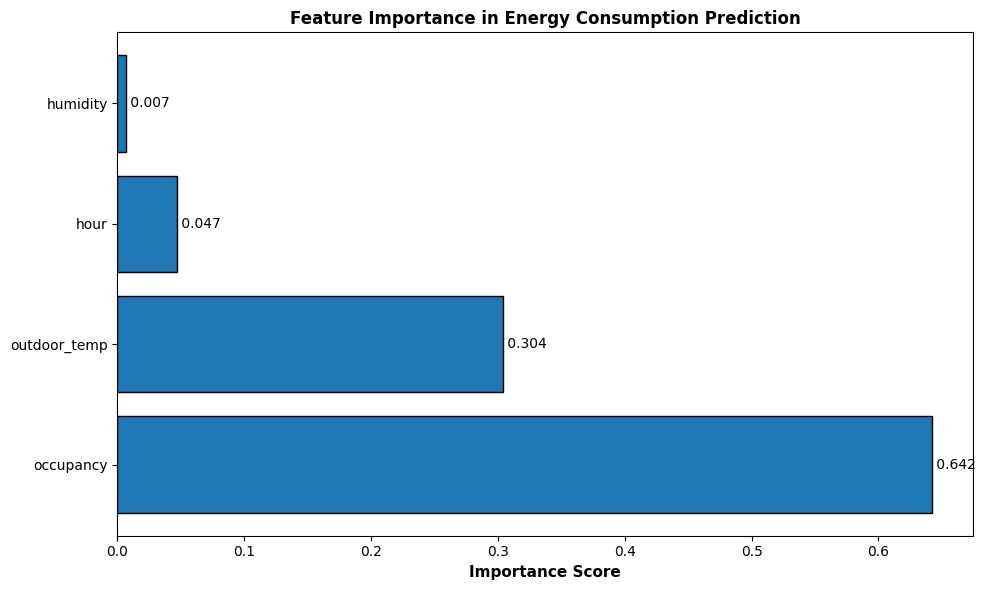


Feature Rankings:
     feature  importance
   occupancy    0.642458
outdoor_temp    0.303957
        hour    0.046632
    humidity    0.006954


In [8]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": energy_model.feature_importances_
}).sort_values("importance", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    feature_importance["feature"],
    feature_importance["importance"],
    edgecolor="black"
)

ax.set_xlabel("Importance Score", fontsize=11, fontweight="bold")
ax.set_title("Feature Importance in Energy Consumption Prediction", fontsize=12, fontweight="bold")

for i, value in enumerate(feature_importance["importance"]):
    ax.text(value, i, f" {value:.3f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

print("\nFeature Rankings:")
print(feature_importance.to_string(index=False))


Building Energy Consumption Model Performance
R² Score: 0.9652
MAE:      2.8009 kWh
RMSE:     3.6008 kWh



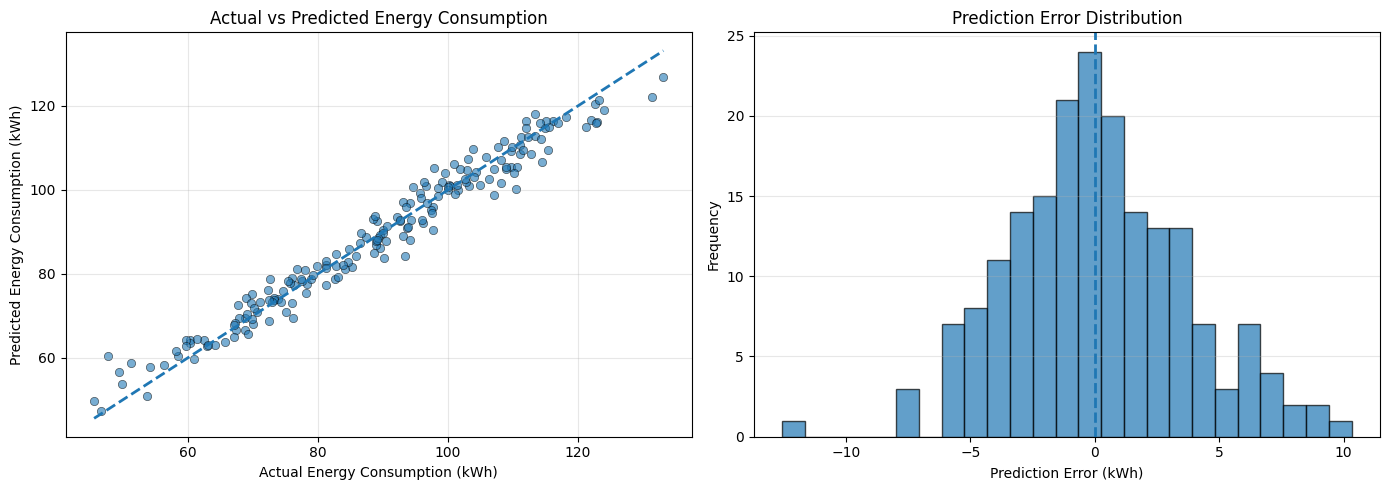

Std deviation of actual values: 19.3651 kWh

Model Summary:
Mean actual energy consumption: 89.3310 kWh
Total test samples: 190


In [9]:
predictions = energy_model.predict(X_test_scaled)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("=" * 50)
print("Building Energy Consumption Model Performance")
print("=" * 50)
print(f"R² Score: {r2:.4f}")
print(f"MAE:      {mae:.4f} kWh")
print(f"RMSE:     {rmse:.4f} kWh")
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, predictions, alpha=0.6, edgecolors="k", linewidth=0.5)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    linewidth=2
)
axes[0].set_xlabel("Actual Energy Consumption (kWh)")
axes[0].set_ylabel("Predicted Energy Consumption (kWh)")
axes[0].set_title("Actual vs Predicted Energy Consumption")
axes[0].grid(True, alpha=0.3)

errors = y_test.values - predictions
axes[1].hist(errors, bins=25, alpha=0.7, edgecolor="black")
axes[1].axvline(x=0, linestyle="--", linewidth=2)
axes[1].set_xlabel("Prediction Error (kWh)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Prediction Error Distribution")
axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print(f"Std deviation of actual values: {y_test.std():.4f} kWh")
print("\nModel Summary:")
print(f"Mean actual energy consumption: {y_test.mean():.4f} kWh")
print(f"Total test samples: {len(y_test)}")

Cross-Validation (5-Fold)
Mean R²: 0.9567 | Std Dev: 0.0078


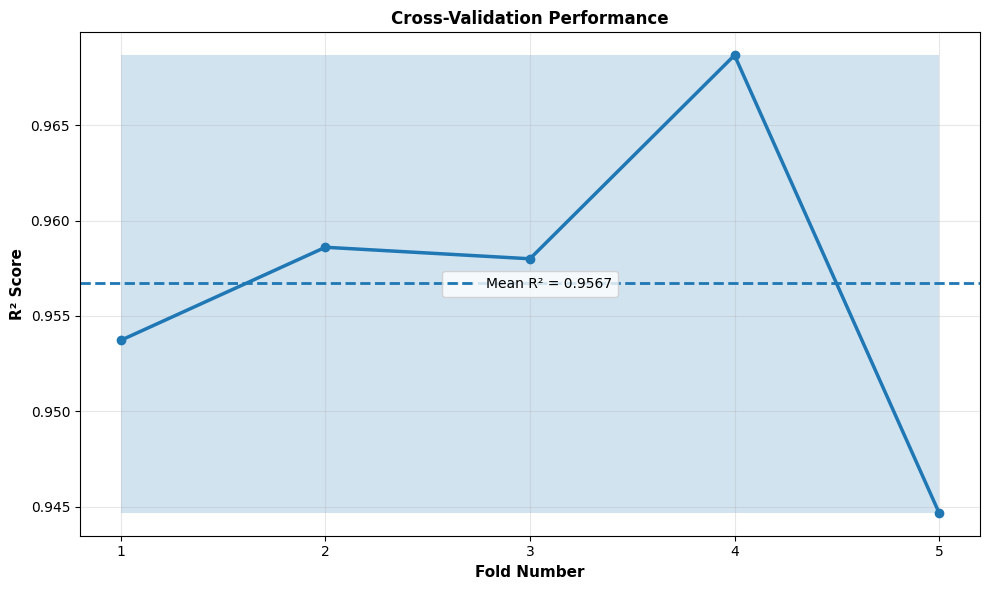

In [10]:

cv_scores = cross_val_score(energy_model, X_train_scaled, y_train, cv=5, scoring="r2")

print("Cross-Validation (5-Fold)")
print(f"Mean R²: {cv_scores.mean():.4f} | Std Dev: {cv_scores.std():.4f}")

fig, ax = plt.subplots(figsize=(10, 6))
folds = np.arange(1, len(cv_scores) + 1)

ax.plot(folds, cv_scores, marker="o", linewidth=2.5)
ax.axhline(cv_scores.mean(), linestyle="--", linewidth=2, label=f"Mean R² = {cv_scores.mean():.4f}")
ax.fill_between(folds, cv_scores.min(), cv_scores.max(), alpha=0.2)

ax.set_xlabel("Fold Number", fontsize=11, fontweight="bold")
ax.set_ylabel("R² Score", fontsize=11, fontweight="bold")
ax.set_title("Cross-Validation Performance", fontsize=12, fontweight="bold")
ax.set_xticks(folds)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()